In [4]:
!pip install skorch -q

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [5]:
#vérification du chemin des fichiers
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


(851264, 7)
        date symbol        open       close         low        high     volume
0 2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000  2163600.0
1 2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001  2386400.0
2 2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998  2489500.0
3 2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002  2006300.0
4 2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002  1408600.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       

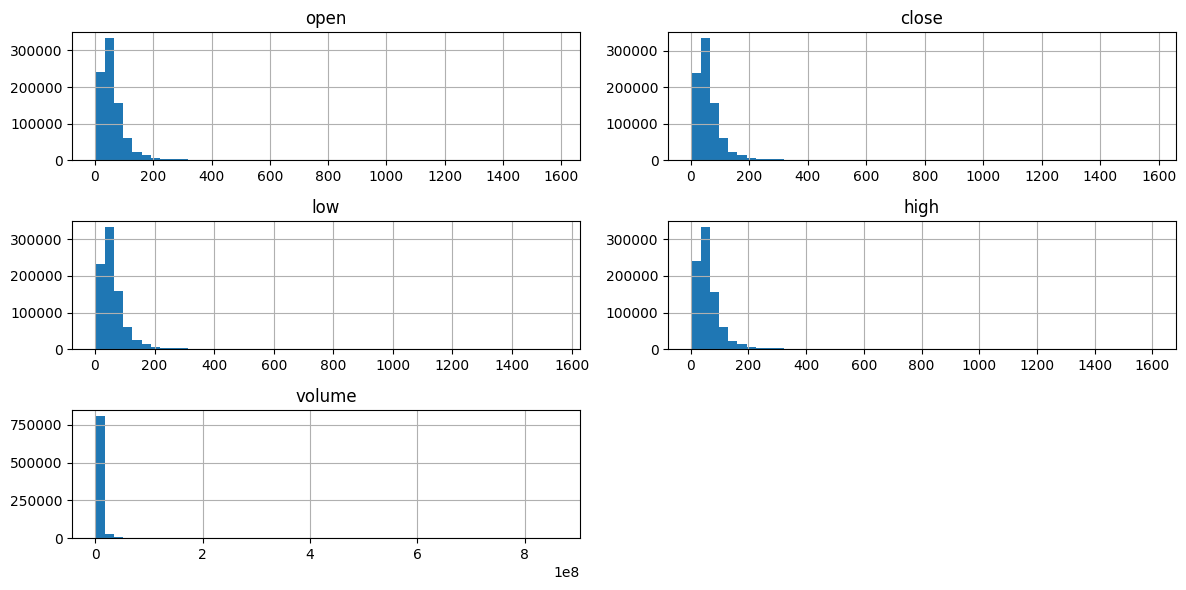

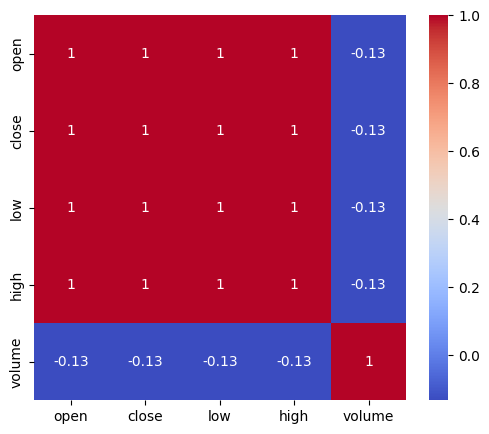

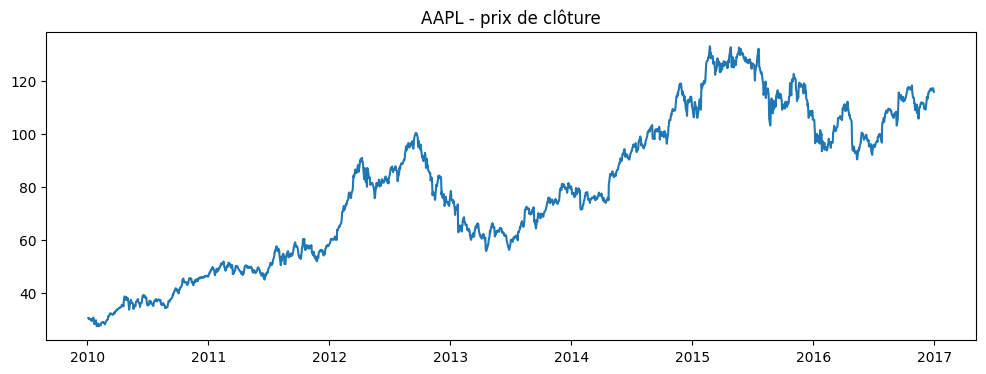

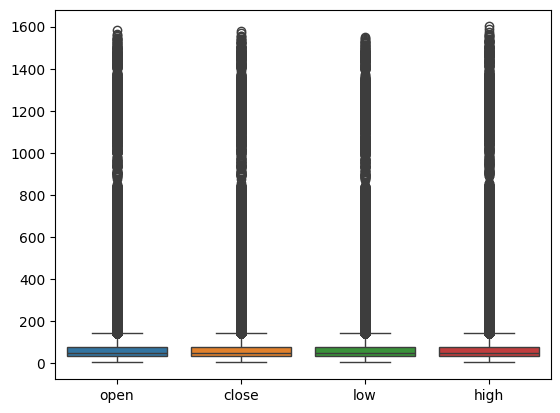

In [6]:
df = pd.read_csv("/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv", parse_dates=["date"])

print(df.shape)
print(df.head())
df.info()
print(df.describe())
print("Valeurs manquantes :\n", df.isnull().sum())
print("Nombre de sociétés :", df["symbol"].nunique())

# Distributions
df[["open","close","low","high","volume"]].hist(bins=50, figsize=(12,6))
plt.tight_layout(); plt.show()

# Corrélations
plt.figure(figsize=(6,5))
sns.heatmap(df[["open","close","low","high","volume"]].corr(), annot=True, cmap="coolwarm")
plt.show()

# Évolution d'une action
aapl = df[df["symbol"]=="AAPL"]
plt.figure(figsize=(12,4))
plt.plot(aapl["date"], aapl["close"])
plt.title("AAPL - prix de clôture"); plt.show()

# Outliers
sns.boxplot(data=df[["open","close","low","high"]]); plt.show()

In [7]:
from torch.utils.data import TensorDataset, DataLoader

features = ["open", "low", "high", "volume"]
X = df[features].copy()
X["volume"] = np.log1p(X["volume"])      # volume très asymétrique
y = df[["close"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation : on "fit" uniquement sur le train (évite la fuite de données)
sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train); X_test = sx.transform(X_test)
y_train = sy.fit_transform(y_train); y_test = sy.transform(y_test)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr, Xte, ytr, yte = map(to_t, [X_train, X_test, y_train, y_test])

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=1024, shuffle=True)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=1024)
print(Xtr.shape, Xte.shape)

torch.Size([681011, 4]) torch.Size([170253, 4])


In [8]:
class MLP(nn.Module):
    def __init__(self, in_dim=4, hidden=(64, 32)):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, 1))   # 1 sortie : régression, pas d'activation
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [12]:
def r2_score_torch(y_true, y_pred):
    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

def evaluate(model, loader, criterion):
    model.eval()
    losses, ys, ps = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            losses.append(criterion(pred, yb).item() * len(xb))
            ys.append(yb); ps.append(pred)
    y_all, p_all = torch.cat(ys), torch.cat(ps)
    return sum(losses) / len(y_all), r2_score_torch(y_all, p_all).item()

def train_model(model, epochs=20, lr=1e-3, opt_cls=torch.optim.Adam, weight_decay=0.0):
    criterion = nn.MSELoss()
    optimizer = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        tr_loss, tr_r2 = evaluate(model, train_loader, criterion)
        te_loss, te_r2 = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss)
        history["train_r2"].append(tr_r2);     history["test_r2"].append(te_r2)
        print(f"Epoch {epoch+1:02d} | loss {tr_loss:.5f}/{te_loss:.5f} | R² {tr_r2:.4f}/{te_r2:.4f}")
    return history

history_base = train_model(model, epochs=20, lr=1e-3)

Epoch 01 | loss 0.00012/0.00012 | R² 0.9999/0.9999
Epoch 02 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 03 | loss 0.00009/0.00009 | R² 0.9999/0.9999
Epoch 04 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 05 | loss 0.00009/0.00009 | R² 0.9999/0.9999
Epoch 06 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 07 | loss 0.00015/0.00015 | R² 0.9999/0.9998
Epoch 08 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 09 | loss 0.00008/0.00008 | R² 0.9999/0.9999
Epoch 10 | loss 0.00008/0.00008 | R² 0.9999/0.9999
Epoch 11 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 12 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 13 | loss 0.00013/0.00013 | R² 0.9999/0.9999
Epoch 14 | loss 0.00013/0.00013 | R² 0.9999/0.9999
Epoch 15 | loss 0.00016/0.00016 | R² 0.9998/0.9998
Epoch 16 | loss 0.00015/0.00015 | R² 0.9999/0.9999
Epoch 17 | loss 0.00007/0.00007 | R² 0.9999/0.9999
Epoch 18 | loss 0.00027/0.00027 | R² 0.9997/0.9997
Epoch 19 | loss 0.00006/0.00007 | R² 0.9999/0.9999
Epoch 20 | loss 0.00009/0.00009

In [10]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV

class MLPSk(nn.Module):
    def __init__(self, n_hidden=64, n_layers=2, in_dim=4):
        super().__init__()
        layers, prev = [], in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(prev, n_hidden), nn.ReLU()]
            prev = n_hidden
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

net = NeuralNetRegressor(
    MLPSk, criterion=nn.MSELoss, optimizer=torch.optim.Adam,
    max_epochs=10, lr=1e-3, batch_size=1024,
    device=device, verbose=0, train_split=None
)

param_grid = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [10, 20],
    "module__n_hidden": [32, 64],
    "module__n_layers": [1, 2],
}

# Sous-échantillon pour aller vite
idx = np.random.RandomState(42).choice(len(Xtr), 50000, replace=False)
X_gs, y_gs = Xtr[idx].numpy(), ytr[idx].numpy()

grid = GridSearchCV(net, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)
grid.fit(X_gs, y_gs)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur R² (CV) :", grid.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Meilleurs paramètres : {'lr': 0.01, 'max_epochs': 20, 'module__n_hidden': 64, 'module__n_layers': 2, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur R² (CV) : 0.9998606244723002


In [11]:
!pip install skorch

In [13]:
bp = grid.best_params_
best_model = MLP(hidden=(bp["module__n_hidden"],) * bp["module__n_layers"]).to(device)
history_best = train_model(best_model, epochs=bp["max_epochs"], lr=bp["lr"], opt_cls=bp["optimizer"])

Epoch 01 | loss 0.00023/0.00023 | R² 0.9998/0.9998
Epoch 02 | loss 0.00012/0.00013 | R² 0.9999/0.9999
Epoch 03 | loss 0.00081/0.00081 | R² 0.9992/0.9992
Epoch 04 | loss 0.00015/0.00016 | R² 0.9998/0.9998
Epoch 05 | loss 0.00010/0.00010 | R² 0.9999/0.9999
Epoch 06 | loss 0.00044/0.00045 | R² 0.9996/0.9996
Epoch 07 | loss 0.00011/0.00011 | R² 0.9999/0.9999
Epoch 08 | loss 0.00026/0.00026 | R² 0.9997/0.9997
Epoch 09 | loss 0.00022/0.00023 | R² 0.9998/0.9998
Epoch 10 | loss 0.00283/0.00285 | R² 0.9972/0.9972
Epoch 11 | loss 0.00071/0.00072 | R² 0.9993/0.9993
Epoch 12 | loss 0.00009/0.00009 | R² 0.9999/0.9999
Epoch 13 | loss 0.00013/0.00013 | R² 0.9999/0.9999
Epoch 14 | loss 0.00055/0.00055 | R² 0.9995/0.9994
Epoch 15 | loss 0.00014/0.00015 | R² 0.9999/0.9999
Epoch 16 | loss 0.00137/0.00138 | R² 0.9986/0.9986
Epoch 17 | loss 0.00590/0.00594 | R² 0.9941/0.9941
Epoch 18 | loss 0.00066/0.00066 | R² 0.9993/0.9993
Epoch 19 | loss 0.00035/0.00035 | R² 0.9997/0.9997
Epoch 20 | loss 0.00079/0.00080

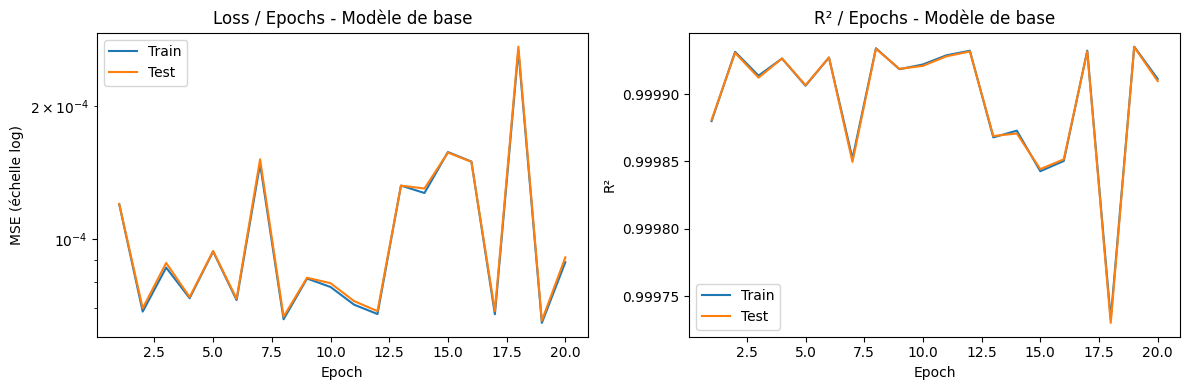

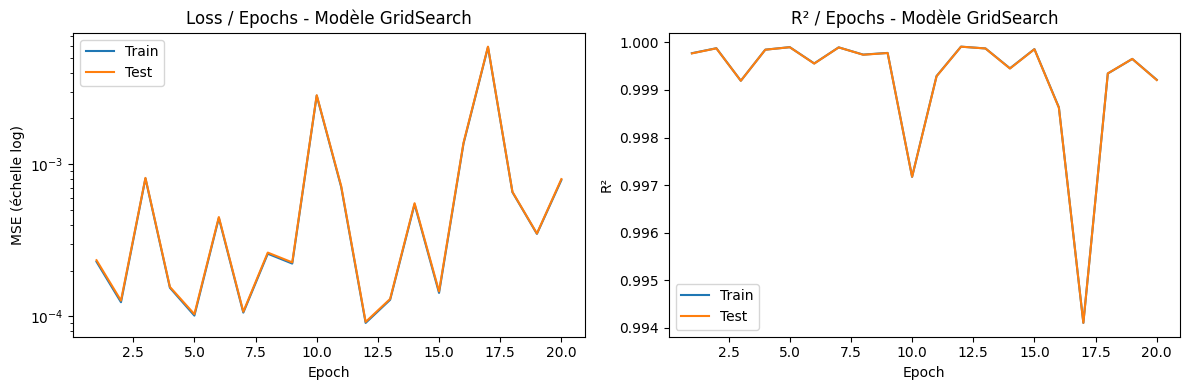

In [22]:
def plot_history(h, title, fname):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, h["train_loss"], label="Train")
    ax[0].plot(epochs, h["test_loss"], label="Test")
    ax[0].set_yscale("log")
    ax[0].set_title(f"Loss / Epochs - {title}")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE (échelle log)")
    ax[0].legend()

    ax[1].plot(epochs, h["train_r2"], label="Train")
    ax[1].plot(epochs, h["test_r2"], label="Test")
    ax[1].set_title(f"R² / Epochs - {title}")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("R²")
    ax[1].legend()

    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

plot_history(history_base, "Modèle de base", "curves_base.png")
plot_history(history_best, "Modèle GridSearch", "curves_best.png")

In [29]:
import copy, time

# Validation = 10 % du train (le test reste intact)
g = torch.Generator().manual_seed(1)
perm = torch.randperm(len(Xtr), generator=g)
n_val = int(0.1 * len(Xtr))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

tr_dl  = DataLoader(TensorDataset(Xtr[tr_idx], ytr[tr_idx]), batch_size=1024, shuffle=True)
val_dl = DataLoader(TensorDataset(Xtr[val_idx], ytr[val_idx]), batch_size=1024)

class RegMLP(nn.Module):
    def __init__(self, in_dim=4, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def run_experiment(name, model_kwargs=None, epochs=20, lr=1e-3,
                   weight_decay=0.0, use_scheduler=False, patience=None):
    torch.manual_seed(0)
    model = RegMLP(**(model_kwargs or {})).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
             if use_scheduler else None)

    hist = {"val_loss": [], "test_loss": [], "test_r2": []}
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()

    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()

        val_loss, _ = evaluate(model, val_dl, criterion)
        te_loss, te_r2 = evaluate(model, test_loader, criterion)
        hist["val_loss"].append(val_loss)
        hist["test_loss"].append(te_loss)
        hist["test_r2"].append(te_r2)

        if sched: sched.step(val_loss)
        if val_loss < best_val:
            best_val, best_epoch, wait = val_loss, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if patience and wait >= patience:
                break

    if patience:                      # early stopping : on restaure les meilleurs poids
        model.load_state_dict(best_state)

    tr_loss, tr_r2 = evaluate(model, tr_dl, criterion)
    te_loss, te_r2 = evaluate(model, test_loader, criterion)
    result = {
        "Modèle": name,
        "R² train": tr_r2, "R² test": te_r2, "MSE test": te_loss,
        "Epochs exécutées": len(hist["test_r2"]),
        "Meilleure epoch (val)": best_epoch,
        "Instabilité (std R² test, 5 dernières epochs)": float(np.std(hist["test_r2"][-5:])),
        "Temps (s)": round(time.time() - t0, 1),
    }
    return result, hist

In [30]:
configs = [
    ("1. Baseline",        {},                    dict()),
    ("2. Weight decay",    {},                    dict(weight_decay=1e-4)),
    ("3. Dropout 0.1",     dict(dropout=0.1),     dict()),
    ("4. BatchNorm",       dict(batchnorm=True),  dict()),
    ("5. Scheduler",       {},                    dict(use_scheduler=True)),
    ("6. Early stopping",  {},                    dict(patience=5)),
    ("7. Combiné",         dict(batchnorm=True),  dict(weight_decay=1e-4, use_scheduler=True, patience=5)),
]

results, histories = [], {}
for name, mk, kw in configs:
    print("Entraînement :", name)
    r, h = run_experiment(name, model_kwargs=mk, **kw)
    results.append(r); histories[name] = h

res = pd.DataFrame(results).set_index("Modèle")
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
res

Entraînement : 1. Baseline
Entraînement : 2. Weight decay
Entraînement : 3. Dropout 0.1
Entraînement : 4. BatchNorm
Entraînement : 5. Scheduler
Entraînement : 6. Early stopping
Entraînement : 7. Combiné


,R² train,R² test,MSE test,Epochs exécutées,Meilleure epoch (val),"Instabilité (std R² test, 5 dernières epochs)",Temps (s)
Modèle,,,,,,,
1. Baseline,0.999926,0.999924,0.000077,20,17,0.000013,122.700000
2. Weight decay,0.999813,0.999809,0.000193,20,16,0.000035,123.300000
3. Dropout 0.1,0.998209,0.998212,0.001801,20,1,0.000443,123.400000
4. BatchNorm,0.999538,0.999533,0.000471,20,13,0.000179,126.400000
5. Scheduler,0.999927,0.999925,0.000076,20,16,0.000005,121.800000
6. Early stopping,0.999935,0.999934,0.000067,20,17,0.000013,121.500000
7. Combiné,0.999751,0.999750,0.000252,10,5,0.000297,65.700000


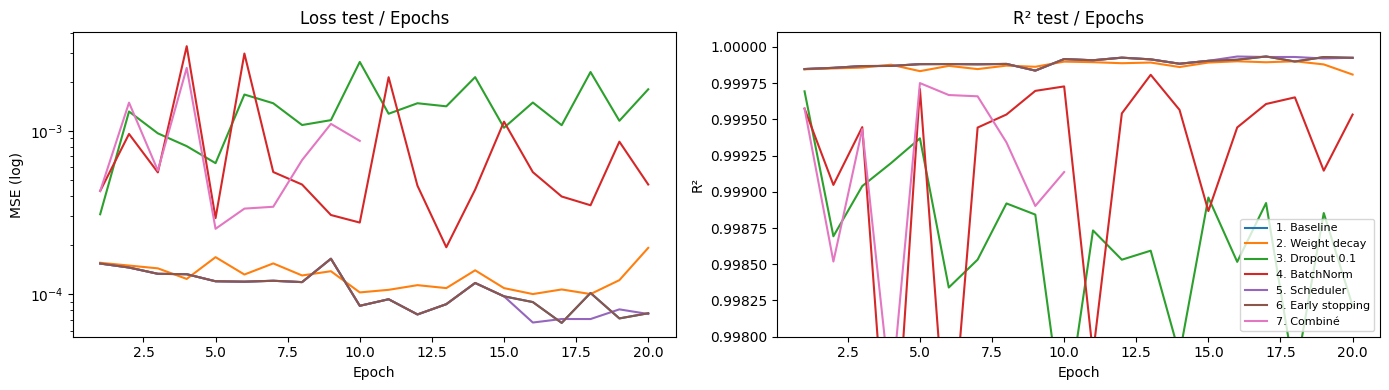

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, h in histories.items():
    ax[0].plot(range(1, len(h["test_loss"]) + 1), h["test_loss"], label=name)
    ax[1].plot(range(1, len(h["test_r2"]) + 1), h["test_r2"], label=name)

ax[0].set_yscale("log"); ax[0].set_title("Loss test / Epochs")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE (log)")
ax[1].set_title("R² test / Epochs"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("R²")
ax[1].set_ylim(0.998, 1.0001)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("regularisation_comparaison.png", dpi=150); plt.show()